# Figure 7b. cis-eGene indirect associations with microglial trans-eProgram 27

Forest plot of the indirect (mediated) effect of the AD-colocalized lead variant on the microglial *trans*-eProgram 27 score through *KNOP1* (eight brain contexts) or *IQCK* (astrocyte) expression. Estimates come from single-mediator models fitted by full-information maximum likelihood (FIML; N = 784 donors in total, 234-386 with complete genotype, mediator and outcome data) with Wald 95% confidence intervals. Orange marks a 95% CI that excludes 0 (nominal; BH-adjusted q-values are printed in the table).

Input: `data/Figure_7b_KNOP1_mediation.rds`

In [1]:
library(ggplot2)
d <- readRDS("data/Figure_7b_KNOP1_mediation.rds")
d

mediator,gene,context,indirect_effect,ci_lower,ci_upper,ci_method,p_value,BH_q,n_total,n_complete,ci_excludes_0
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<int>,<int>,<lgl>
KNOP1 (Ast),KNOP1,Ast,0.53771765,0.28562938,0.7898059,Wald 95%,2.906039e-05,0.0002615435,784,386,TRUE
KNOP1 (Exc),KNOP1,Exc,0.38189143,0.14769586,0.6160870,Wald 95%,1.393381e-03,0.0062702123,784,386,TRUE
KNOP1 (Oli),KNOP1,Oli,0.34459045,0.07311089,0.6160700,Wald 95%,1.285386e-02,0.0313395255,784,386,TRUE
KNOP1 (DLPFC),KNOP1,DLPFC,0.20138276,-0.10179342,0.5045589,Wald 95%,1.929530e-01,0.2894294291,784,386,FALSE
KNOP1 (Inh),KNOP1,Inh,0.17159279,-0.01159834,0.3547839,Wald 95%,6.637641e-02,0.1194775459,784,386,FALSE
IQCK (Ast),IQCK,Ast,0.12695006,0.02576760,0.2281325,Wald 95%,1.392868e-02,0.0313395255,784,386,TRUE
KNOP1 (PCC),KNOP1,PCC,-0.07412909,-0.31666016,0.1684020,Wald 95%,5.491337e-01,0.6177754686,784,234,FALSE
KNOP1 (OPC),KNOP1,OPC,0.05827296,-0.09492197,0.2114679,Wald 95%,4.559455e-01,0.5862156977,784,385,FALSE
KNOP1 (AC),KNOP1,AC,-0.02508639,-0.25159664,0.2014239,Wald 95%,8.281543e-01,0.8281543321,784,305,FALSE


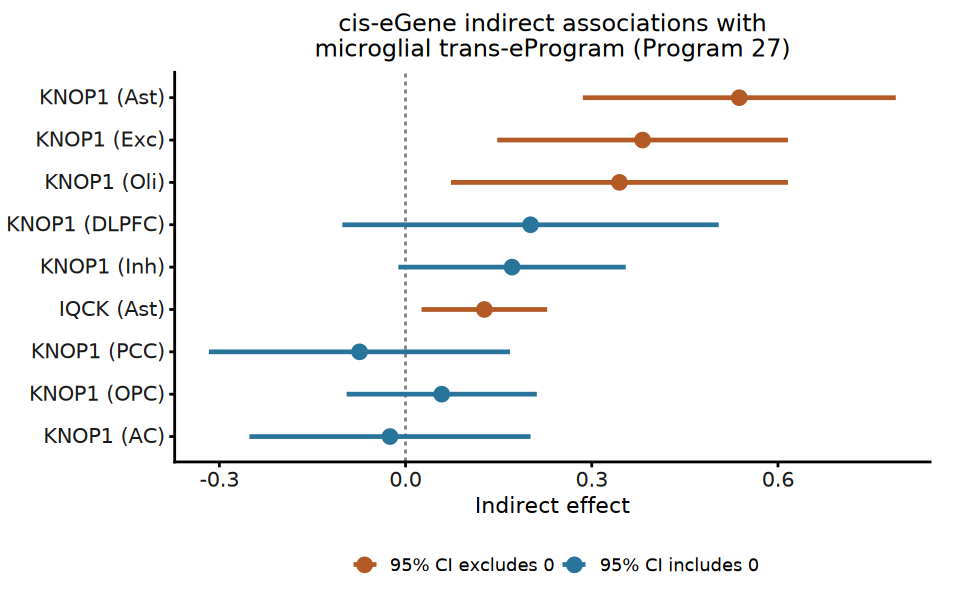

In [2]:
TITLE <- "cis-eGene indirect associations with
microglial trans-eProgram (Program 27)"
d <- d[order(-abs(d$indirect_effect), d$mediator), ]
d$mediator <- factor(d$mediator, levels = rev(d$mediator))
gene <- sub(" \\(.*$", "", levels(d$mediator))
ctx  <- sub("^.* \\((.*)\\)$", "\\1", levels(d$mediator))
labs_expr <- parse(text = paste0('italic("', gene, '")~"(', ctx, ')"'))
d$status <- ifelse(d$ci_excludes_0, "95% CI excludes 0", "95% CI includes 0")

p <- ggplot(d, aes(x = indirect_effect, y = mediator, colour = status)) +
  geom_vline(xintercept = 0, linetype = 2, colour = "grey50") +
  geom_errorbar(aes(xmin = ci_lower, xmax = ci_upper), orientation = "y", width = 0, linewidth = 1) +
  geom_point(size = 3.5) +
  scale_colour_manual(values = c("95% CI excludes 0" = "#B35A27", "95% CI includes 0" = "#28749A")) +
  scale_y_discrete(labels = labs_expr) +
  labs(title = TITLE, x = "Indirect effect", y = NULL, colour = NULL) +
  theme_classic(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5, size = 14),
        axis.text = element_text(colour = "grey10", size = 12),
        legend.position = "bottom",
        plot.margin = margin(8, 18, 6, 6))

options(repr.plot.width = 8, repr.plot.height = 5)
p